# 3.0 Building and Validating an OMX Kinematic Model

**ELEC3901 Robotic Manipulators, Lab 3** (week 3: Forward Kinematics and Geometric Modelling)

<br>

Read before this lab: the week 3 lecture and RVC3 Ch. 7.1 to 7.2. Each section below follows the lecture slides listed next to it.

### Contents

| Section | Where | Time | Lecture slides |
|---|---|---|---|
| [3.1 Forward kinematics in the plane](#plane) | desk | 15 min | 5-11: The forward kinematics problem; Configuration and pose; OMX shoulder and elbow in the plane |
| [3.2 The OMX-F as an ETS](#ets) | desk | 20 min | 12-13: Elementary Transform Sequence (ETS); The OMX-F as an ETS |
| [3.3 Denavit-Hartenberg parameters](#dh) | desk | 20 min | 14-29: Complete? Why a convention; D-H: four parameters; D-H and the transform matrix; D-H procedure; D-H example: an RPR robot; D-H on the OMX-F; Checked against the ETS; Standard vs modified D-H; Why D-H? |
| [3.4 Workspace by sampling](#ws) | desk | 5 min | 32: Workspace by sampling |
| [3.5 On the arm: the model against the arm](#arm) | arm | 15 min | 7: Links, joints and joint variables |
| [3.6 On the arm: the camera as an instrument](#camera) | arm | 30 min | 31: URDF, and nominal vs actual; 34: Practical: Lab 3 |
| [3.7 The whole lab with the toolbox](#tb) | desk | 5 min | 33: The Robotics Toolbox in practice |

**How this notebook works.** Each section gives the maths from the lecture, a worked case in code, then the next case for you to
write: a *Task* (a function, checked against hidden values) or an *Exercise* (a few lines with `...` blanks, checked against the
toolbox by `try_it`, which prints `OK` or what looks wrong). Each section ends with the same result from `spatialmath`, the way you
will usually do it. *Desk* sections need no arm: do them before the session if you can. Sections marked *(stretch)* are for when
the core is done. A **Hint** opens when you click it - try without it first.

*Notation.* The pose of the tool frame {E} in the base frame {B} is ${}^{B}\mathbf{T}_{E}$ (Corke), `T_BE` in code. Corke writes
the elementary transforms $\mathbf{T}_z(d)$ (a translation along z) and $\mathbf{R}_y(q)$ (a rotation about y). Positive pitch is
**nose down** throughout, as on the arm. Lengths in the text are millimetres; the code works in metres.
Equations are numbered (1), (2), ... through the notebook; the code comments refer to them.

**Checkpoint for sign-off:** Validated OMX model committed to your LABS repository; camera-measured error table and error-field plot

Reference versions of previous weeks' tasks are imported from `omx_ref.py`, so last week never blocks this week; the functions you
write here are the ones your assignment will be built from.

> **Safety.** Keep the workspace clear of hands and cables before enabling torque, and set a conservative profile velocity
> (`arm.set_profile(60, 20)` or lower) before commanding motion. If anything unexpected happens, press the power isolator on the
> bench first, then think. Torque off (`arm.torque(False)`) before touching the arm.

The imports for this notebook. Section 3.5 connects to the arm; nothing before it needs the arm or the camera.

In [ ]:
import sys, os
# Repository layout: weekNN/ (notebooks), scripts/ (helper modules), data/ (your measurements, shared by every week).
for _up in ('.', '..', os.path.join('..', '..')):
    if os.path.isdir(os.path.join(_up, 'scripts')):
        _root = os.path.abspath(_up); sys.path.insert(0, os.path.join(_root, 'scripts'))
        os.makedirs(os.path.join(_root, 'data'), exist_ok=True); os.chdir(os.path.join(_root, 'data'))   # files save/load here
        break
import numpy as np, matplotlib.pyplot as plt, time, cv2
import roboticstoolbox as rtb
from spatialmath import SE3, SO3, SE2, UnitQuaternion
from spatialmath.base import trplot, tranimate
from omx_model import omx_robot, omx_ik, Q_LIM, T_EC, P_TIP_E, mount_tilt, look_down_pitch
from omx import OMX
from omx_camera import Camera, tip_in_mat, predicted_T_CM, pose_error
from omx_calib import small_T
from labcheck import check, try_it
NOM = dict(d1=0.0975, l2z=0.11315, l2x=0.0415, l3=0.162, l4=0.123)   # nominal link parameters (m)
from omx_ref import R_to_rpy, chain_T_BM, inv_T, make_T, mount_from_views, rot2, rot_about, rotx, roty, rotz, rpy_to_R, se2, step_log, transform_point, transform_points, transl2, trot2   # reference versions of PREVIOUS labs' tasks; your own definitions below override them
np.set_printoptions(precision=4, suppress=True)
%matplotlib inline
omx = omx_robot()              # Robotics Toolbox model (nominal)
T_EC_CAD = T_EC   # the design camera mount (ROBOTIS CAD: optical axis 38 deg below the tool). Each arm's camera sits a little differently: Lab 2
                  # measures yours, and from Lab 3 on the MOUNT cell re-measures it every session and replaces T_EC
HOVER = 0.09      # tip hover height with the tool vertical: the OMX-F reaches r ~ 0.24 m there (touching the mat: r ~ 0.28 m)
CAM_HOVER = 0.15  # tip height for camera measurements, tool pitched with look_down_pitch(T_EC) so the camera looks straight down:
                  # the camera is then ~180 mm up, enough to see the marker ring around the clear zone

<br>

<a id='plane'></a>

### 3.1 Forward kinematics in the plane (desk)
---

Forward kinematics turns the joint angles into the pose of the tool, ${}^{B}\mathbf{T}_{E} = \mathcal{K}(q)$: always exactly one
answer. Before any matrices, the geometry. Joint 1 turns a vertical plane; joints 2, 3 and 4 pitch inside it. So describe the tip by
its reach $r$ from the joint-1 axis and its height $z$ above the mat.

Link 2 is an L: up $l_{2z}$ = 113.15 mm, then forward $l_{2x}$ = 41.5 mm. Replace it by the straight line from the shoulder axis to
the elbow axis, of length $a_2$, which leans $\beta$ forward of vertical when $q_2 = 0$:

$$ a_2 = \sqrt{l_{2x}^2 + l_{2z}^2}, \qquad \beta = \operatorname{atan2}(l_{2x},\, l_{2z}) \qquad (1) $$

Each link then adds one term: its length times the cosine of its angle below the horizontal to $r$, and minus its length times the
sine of that angle to $z$. The angles add along the chain, and the tool pitch is $\theta = q_2 + q_3 + q_4$:

$$ r = a_2\sin(q_2+\beta) + l_3\cos(q_2+q_3) + l_4\cos\theta, \qquad
   z = d_1 + a_2\cos(q_2+\beta) - l_3\sin(q_2+q_3) - l_4\sin\theta \qquad (2) $$

Finally the yaw turns the plane: $x = r\cos q_1$, $y = r\sin q_1$. $\qquad (3)$

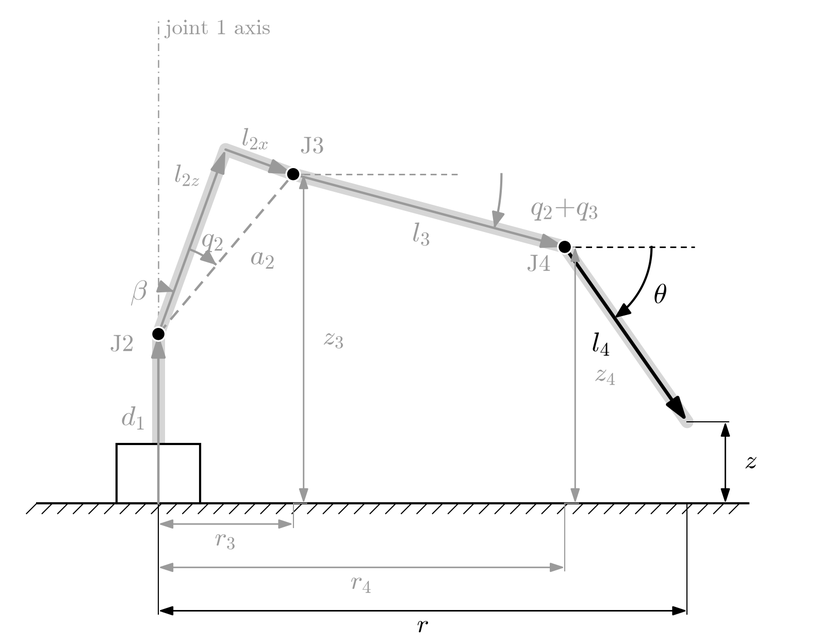

*The lecture's example pose, q = (0, 20, -5, 40) degrees, chosen so every angle is visible: link 2 replaced by a2
    at beta from vertical, link 3 at q2 + q3 below the horizontal, the tool at theta. Equation (2) adds one term per link.*

In [ ]:
# --- worked case: the tip at home from the plane formulas, equations (1) and (2) ---------------------------------------
d1, l2z, l2x, l3, l4 = NOM['d1'], NOM['l2z'], NOM['l2x'], NOM['l3'], NOM['l4']
a2, beta = np.hypot(l2x, l2z), np.arctan2(l2x, l2z)                     # (1)
q1, q2, q3, q4 = np.radians([0, -60, 60, 30])                           # home
th = q2 + q3 + q4
r = a2 * np.sin(q2 + beta) + l3 * np.cos(q2 + q3) + l4 * np.cos(th)     # (2)
z = d1 + a2 * np.cos(q2 + beta) - l3 * np.sin(q2 + q3) - l4 * np.sin(th)
print(f'a2 = {1e3 * a2:.1f} mm, beta = {np.degrees(beta):.1f} deg')
print(f'home: r = {1e3 * r:.1f} mm, z = {1e3 * z:.1f} mm, tool pitch {np.degrees(th):.0f} deg   (the lecture: 191.3, 128.5, 30)')

**Exercise 3.1: the tip from the plane formulas.** Use equations (1)-(3) to find the tip position and the tool pitch for
$q = (30°, 20°, -5°, 40°)$, the figure's pose with the base turned 30 degrees. The check compares them with the toolbox.
*Why:* this is all forward kinematics is - geometry, one term per link. The matrices in 3.2 are a tidier way to write the same sum,
and once you have done it by hand you can sanity-check any pose in your head.

In [ ]:
# --- Exercise 3.1: the tip from the plane formulas ------------------------------------------------------------------
q1, q2, q3, q4 = np.radians([30, 20, -5, 40])
r = ...                            # equation (2)
z = ...
p = ...                            # [x, y, z] (m), equation (3)
pitch = ...                        # the tool pitch theta (rad)
T_tb = omx.fkine([q1, q2, q3, q4])
try_it('tip position (m)', p, T_tb.t)
try_it('tool pitch (rad)', pitch, np.arctan2(-T_tb.R[2, 0], np.hypot(T_tb.R[0, 0], T_tb.R[1, 0])))

<details><summary><b>Hint</b></summary>

Copy the worked case and change the angles. Link 2 is measured from the vertical (sine for $r$, cosine for $z$); links 3 and 4 from
the horizontal (cosine for $r$, minus sine for $z$). The yaw only splits $r$ into $x$ and $y$.

</details>

<br>

<a id='ets'></a>

### 3.2 The OMX-F as an ETS (desk)
---

An elementary transform sequence (ETS) writes the pose as a product of the simplest transforms: a translation along one axis or a
rotation about one axis. Constant factors are the link geometry, variable ones the joints. Read left to right, each acts in the frame
the previous ones left you in - rotations turn the axes, translations move along the turned axes. The OMX-F takes nine factors:

$$ {}^{B}\mathbf{T}_{E} = \mathbf{T}_z(d_1)\,\mathbf{R}_z(q_1)\,\mathbf{R}_y(q_2)\,\mathbf{T}_z(l_{2z})\,\mathbf{T}_x(l_{2x})\,
   \mathbf{R}_y(q_3)\,\mathbf{T}_x(l_3)\,\mathbf{R}_y(q_4)\,\mathbf{T}_x(l_4) \qquad (4) $$

The L-shaped link 2 needs no trigonometry here: two translations walk round the corner.

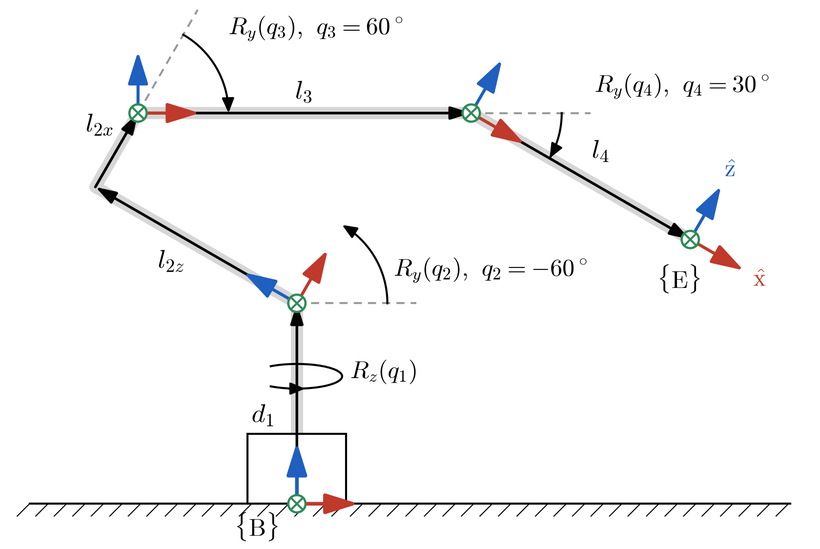

*Equation (4) at home, q = (0, -60, 60, 30) degrees: each black arrow is one translation, taken along the frame's
    own axes after the rotations before it. At each joint, the frame after its rotation (x red, z blue, y into the page) and the angle
    from the previous x direction (dashed); Rz(q1) turns about the base axis. The final frame is {E}, at the closed fingertips.*

In [ ]:
# --- worked case: the first five factors of equation (4) at home, one at a time ------------------------------------------
q = np.radians([0, -60, 60, 30])
T = SE3()
for name, E in [('Tz(d1)', SE3.Tz(NOM['d1'])), ('Rz(q1)', SE3.Rz(q[0])), ('Ry(q2)', SE3.Ry(q[1])),
                ('Tz(l2z)', SE3.Tz(NOM['l2z'])), ('Tx(l2x)', SE3.Tx(NOM['l2x']))]:
    T = T * E
    print(f'after {name:8s} the frame origin is at (x, z) = ({1e3 * T.t[0]:7.1f}, {1e3 * T.t[2]:6.1f}) mm')
print('Tz(l2z) went up AND back: R_y(q2 = -60 deg) had tilted the frame back.  (the lecture: (-98.0, 154.1), then (-77.2, 190.0))')

**Exercise 3.2a: finish the walk.** The worked case multiplied the first five factors of equation (4); multiply the last four to reach
the fingertips at home. *Why:* walking an ETS one factor at a time is how you check a model by hand. After each factor you know where
the frame should be, so a wrong sign or length shows up at the step where it happens.

In [ ]:
# --- Exercise 3.2a: finish the walk ---------------------------------------------------------------------------------
T_walk = ...                       # T times the last four factors of equation (4) (SE3.Ry, SE3.Tx with q and NOM)
try_it('B_T_E at home', T_walk, omx.fkine(q))

<details><summary><b>Hint</b></summary>

Carry on from `T` where the worked case stopped, in the order of equation (4): `SE3.Ry(q[2])`, then `SE3.Tx(NOM['l3'])`, then
`SE3.Ry(q[3])`, then `SE3.Tx(NOM['l4'])`, each multiplied on the right.

</details>

**Exercise 3.2b: predict the tip at q = 0.** At the zero pose link 2 stands up and links 3 and 4 lie level. Write down where the tip is
from the link dimensions alone, before you run anything. *Why:* $q = 0$ is the easiest pose to check a model at, and it is not home.
Knowing it lets you catch a sign or offset mistake in Task 1 at a glance.

In [ ]:
# --- Exercise 3.2b: predict the tip at q = 0 ------------------------------------------------------------------------
my_guess = ...                     # [x, y, z] (m), from the link dimensions only
try_it('tip at the zero pose', my_guess, omx.fkine(np.zeros(4)).t, tol=1e-4)

<details><summary><b>Hint</b></summary>

With every angle zero, each rotation in equation (4) is the identity, so only the translations are left. Add up the ones along z and
the ones along x.

</details>

### Task 1 — Forward kinematics of the OMX in NumPy
From the elementary transform sequence derived in the lecture — `tz(d1) Rz(q1) Ry(q2) tz(l2z) tx(l2x) Ry(q3) tx(l3) Ry(q4) tx(l4)` —
write `omx_fk(q, p)` returning the 4x4 end-effector pose. `p` is a dict like `NOM`. Use your `rotz`/`roty` from Lab 2 (re-defined
below for convenience). Only after the checks pass, compare with `omx.fkine(q)` from the toolbox.

In [ ]:
def roty(a):
    c, s = np.cos(a), np.sin(a); return np.array([[c, 0, s], [0, 1, 0], [-s, 0, c]])
def rotz(a):
    c, s = np.cos(a), np.sin(a); return np.array([[c, -s, 0], [s, c, 0], [0, 0, 1]])
def omx_fk(q, p=NOM):
    """Joint angles q (4,) rad, link parameters p -> 4x4 end-effector pose in the base frame."""
    # TODO: write your implementation here
    raise NotImplementedError


In [ ]:
# --- self-check (hidden expected values) ---------------------------------------------------------
check('zero pose (q = 0) position', lambda: omx_fk(np.zeros(4))[:3, 3], 'fa0b3c835f', decimals=4)
check('position at q = (0.3, 0.5, -0.2, 0.4)', lambda: omx_fk(np.array([0.3, 0.5, -0.2, 0.4]))[:3, 3], '9fa6f4171d', decimals=4)
check('orientation at q = (0.3, 0.5, -0.2, 0.4)', lambda: omx_fk(np.array([0.3, 0.5, -0.2, 0.4]))[:3, :3], '6a6fb96bc6', decimals=4)
check('longer forearm moves the tip', lambda: omx_fk(np.zeros(4), dict(NOM, l3=0.150))[:3, 3], '4a1ce4551c', decimals=4)

<details><summary><b>Hint</b></summary>

Keep a running rotation: `R1 = rotz(q[0])`, `R2 = R1 @ roty(q[1])`, and so on. A translation along the *current* frame's axis is the
rotation so far times the local vector: the step $\mathbf{T}_z(l_{2z})\,\mathbf{T}_x(l_{2x})$ adds `R2 @ [l2x, 0, l2z]`. The final
rotation is `R4`, the final position the sum of the steps.

</details>

**With the toolbox.** `omx` is built from the same ETS (`omx_model.omx_ets()`); `fkine` returns an `SE3`.

In [ ]:
print(omx.ets())
for qt in (np.zeros(4), np.array([0.3, 0.5, -0.2, 0.4]), np.array([-1.0, 0.9, -0.6, 1.2])):
    try_it(f'omx_fk at q = {qt}', lambda: omx_fk(qt), omx.fkine(qt).A)

<br>

<a id='dh'></a>

### 3.3 Denavit-Hartenberg parameters (desk)
---

The ETS is complete but not unique. D-H is an ETS with rules: Denavit and Hartenberg fix one frame per link by rule, after which each
joint is exactly four elementary transforms, so four numbers. The lecture worked an RPR robot; here you do the OMX-F, frame by frame.
Standard form (RVC3 7.1.2): $\hat{z}_{i-1}$ lies on the axis of joint $i$, $\hat{x}_i$ along the common normal from $\hat{z}_{i-1}$ to
$\hat{z}_i$, and

$$ \mathbf{A}_i = \mathbf{R}_z(\theta_i)\,\mathbf{T}_z(d_i)\,\mathbf{T}_x(a_i)\,\mathbf{R}_x(\alpha_i), \qquad
   {}^{0}\mathbf{T}_{4} = \mathbf{A}_1\,\mathbf{A}_2\,\mathbf{A}_3\,\mathbf{A}_4 \qquad (5) $$

$\theta_i$ is the joint angle plus a constant offset; $d_i$ slides along $\hat{z}_{i-1}$ to the common normal; $a_i$ is the length of
the normal; $\alpha_i$ twists $\hat{z}_{i-1}$ onto $\hat{z}_i$ about $\hat{x}_i$.

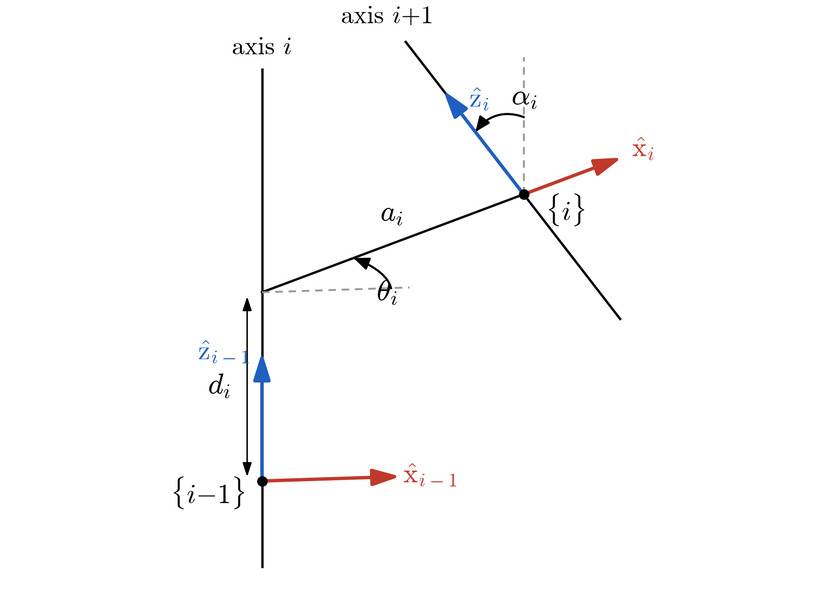

*The four standard D-H parameters between frames {i-1} and {i}.*

**The OMX-F, frame by frame** (at the zero pose, $q = 0$: link 2 near vertical, links 3 and 4 level).

1. **Label the axes.** Axis 1 is vertical; axes 2, 3 and 4 are horizontal and parallel. $\hat{z}_{i-1}$ goes on axis $i$: $\hat{z}_0$ is
   vertical, $\hat{z}_1, \hat{z}_2, \hat{z}_3$ horizontal.
2. **{0}**: on the mat under axis 1, $\hat{z}_0$ up, $\hat{x}_0$ forward. This is {B}.
3. **{1}**: $\hat{z}_1$ on axis 2. Axes 1 and 2 intersect at the shoulder, so $a_1 = 0$, the origin is there and $d_1$ = 97.5 mm. Keep
   $\hat{x}_1 = \hat{x}_0$; then $\alpha_1 = -90°$ turns $\hat{z}_0$ onto $\hat{z}_1$ (along $+\hat{y}_0$, so positive $q_2$ pitches the arm
   forward, as in the ETS). The same pattern as the RPR's first row.
4. **{2}**: $\hat{z}_2$ on axis 3, parallel to $\hat{z}_1$. The common normal is the straight line from shoulder to elbow: $a_2$, $\alpha_2 = 0$,
   $d_2 = 0$. When the servo reads $q_2 = 0$ that line leans $\beta$ forward of vertical while $\hat{x}_1$ is horizontal, so $\theta_2$ needs a
   constant offset: Exercise 3.3a.
5. **{3}**: $\hat{z}_3$ on axis 4, parallel again: $a_3 = l_3$ along link 3, and the opposite offset turns $\hat{x}_3$ back along the link.
6. **{4}**: there is no axis 5 in our model (the roll is locked), so {4} goes at the fingertips with $\hat{x}_4$ along link 4: $a_4 = l_4$,
   $\theta_4 = q_4$.

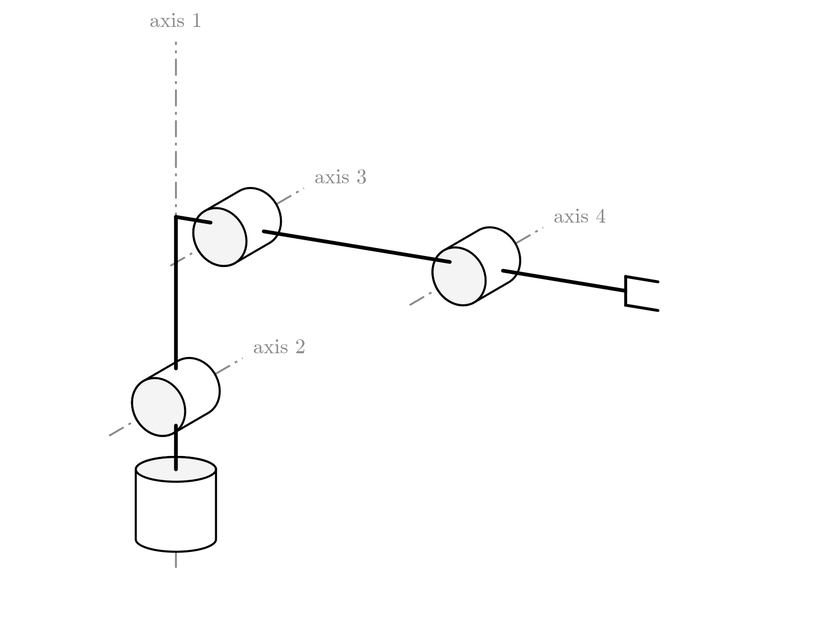

*Step 1: the OMX-F at q = 0 with its four joint axes, drawn as a standard D-H diagram (revolute joints as cylinders).*

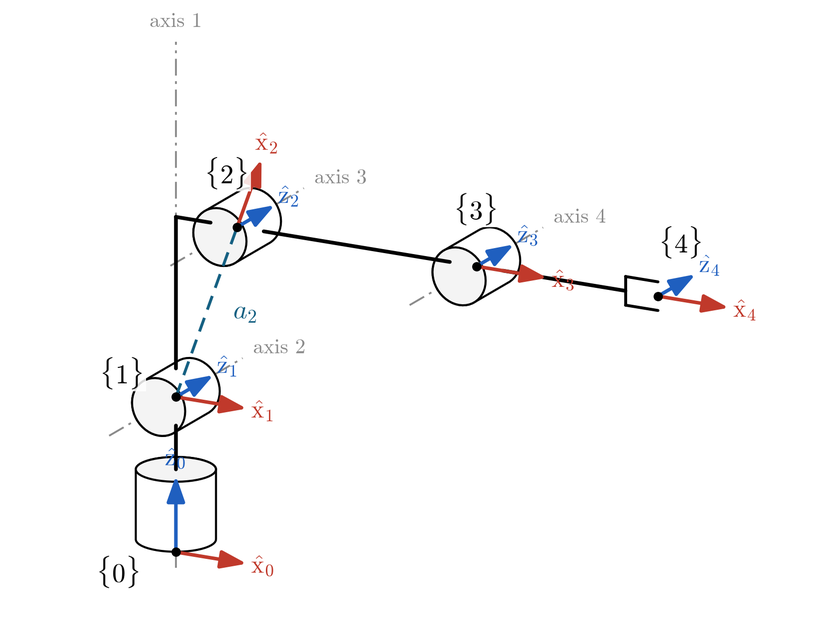

*Steps 2-6: the standard D-H frames on the OMX-F at q = 0 (x red, z blue). z1, z2, z3 lie on the parallel pitch
    axes; the dashed line is the common normal a2 from the shoulder to the elbow, in place of the L-shaped link 2.*

In [ ]:
# --- worked case: row 1 of the table, A_1, equation (5) -----------------------------------------------------------------
from omx_model import omx_dh                                   # the module's D-H model, used for the checks below
# axes 1 and 2 intersect at the shoulder: a1 = 0, d1 up to it; alpha1 = -90 deg turns z0 (up) onto z1 (the joint-2 axis)
A1 = SE3.Rz(0.0) * SE3.Tz(NOM['d1']) * SE3.Tx(0.0) * SE3.Rx(-np.pi / 2)
print(A1)
print('z1 =', np.round(A1.R[:, 2], 3), '= +y0: positive q2 pitches the arm forward, as R_y(q2) does in the ETS')

**Exercise 3.3a: row 2 of the D-H table.** Find $a_2$, the offset on $\theta_2$ and $\alpha_2$. Axes 2 and 3 are parallel, so the common
normal is the straight line from the shoulder to the elbow, $a_2$ of equation (1). At $q_2 = 0$ that line leans $\beta$ forward of
vertical while $\hat{x}_1$ is horizontal: the offset on $\theta_2$ turns $\hat{x}_1$ onto it about $\hat{z}_1$. *Why:* this is the one
row where the OMX-F's L-shaped link 2 shows up in the table, as a constant offset. Task 2 needs it, and the same idea turns up on any
arm whose link does not run straight from one joint to the next.

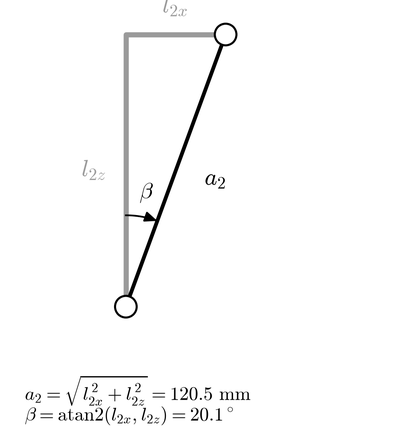

*The l2x step absorbed: the straight common normal a2 at beta from vertical.*

In [ ]:
# --- Exercise 3.3a: row 2 of the D-H table --------------------------------------------------------------------------
a2_dh = ...                        # the length of the common normal (m)
theta2_offset = ...                # theta2 = q2 + theta2_offset (rad)
alpha2 = ...                       # the twist between z1 and z2 (rad)
L2 = omx_dh().links[1]
try_it('a2', a2_dh, L2.a); try_it('theta2 offset', theta2_offset, L2.offset); try_it('alpha2', alpha2, L2.alpha)

<details><summary><b>Hint</b></summary>

A rotation by $\theta$ about $\hat{z}_1$ (= $+\hat{y}_0$) takes $\hat{x}$ to $(\cos\theta, 0, -\sin\theta)$. The elbow line points
$(\sin\beta, 0, \cos\beta)$, so $\cos\theta = \sin\beta$ and $\sin\theta = -\cos\beta$: $\theta = \beta - 90°$.

</details>

### Task 2 — Denavit-Hartenberg table and its forward kinematics
Write the standard DH table you derived on paper as `dh_table()` → array of rows `[theta_offset, d, a, alpha]` for joints 1-4,
and `fk_dh(q, dh)` that multiplies the standard link transforms `Rz(theta) Tz(d) Tx(a) Rx(alpha)` with `theta = q_i + offset_i`.
Its **position** must agree with `omx_fk`; its final-frame orientation may differ (why?).

Hint: fold the 41.5 mm shoulder step (l2x) into one link of length `sqrt(l2x^2 + l2z^2)` with a constant offset `beta = atan2(l2x, l2z)`;
the first link needs `alpha = -pi/2` so that positive joint 2 pitches the arm forward like the ETS model.

In [ ]:
def dh_table(p=NOM):
    """Standard DH rows [theta_offset, d, a, alpha] for joints 1..4 (4x4 array)."""
    # TODO: write your implementation here
    raise NotImplementedError

def fk_dh(q, dh):
    """Standard DH forward kinematics -> 4x4 pose."""
    # TODO: write your implementation here
    raise NotImplementedError


In [ ]:
# --- self-check (hidden expected values) ---------------------------------------------------------
check('DH position at q = 0 = ETS position', lambda: fk_dh(np.zeros(4), dh_table())[:3, 3], 'fa0b3c835f', decimals=4)
check('DH position at (0.3, 0.5, -0.2, 0.4)', lambda: fk_dh(np.array([0.3, 0.5, -0.2, 0.4]), dh_table())[:3, 3], '9fa6f4171d', decimals=4)
check('DH position at (-1.0, 0.9, -0.6, 1.2)', lambda: fk_dh(np.array([-1.0, 0.9, -0.6, 1.2]), dh_table())[:3, 3], '4c49a5e75e', decimals=4)

<details><summary><b>Hint: the table</b></summary>

The whole table (lecture slide 26), rows `[theta_offset, d, a, alpha]`:
joint 1 `[0, d1, 0, -pi/2]`; joint 2 `[beta - pi/2, 0, a2, 0]`; joint 3 `[pi/2 - beta, 0, l3, 0]`; joint 4 `[0, 0, l4, 0]`.
The offsets on joints 2 and 3 cancel along the chain, so the elbow and wrist frames point along links 3 and 4 again.

</details>

**Checked against the ETS.** The two models must agree on the tip position. They do not agree on the end frame: D-H put $\hat{z}_4$
along the joint axes, where the ETS's {E} has its $\hat{y}$. The difference is one constant rotation, the same at every pose.

In [ ]:
rng = np.random.default_rng(1); Qr = rng.uniform(Q_LIM[:, 0], Q_LIM[:, 1], size=(5, 4))
try_it('fk_dh positions at 5 random poses', lambda: [fk_dh(qr, dh_table())[:3, 3] for qr in Qr], [omx.fkine(qr).t for qr in Qr])

In fact ${}^{B}\mathbf{T}_{E}(q) = {}^{0}\mathbf{T}_{4}(q)\,\mathbf{R}_x(90°)$ at every pose (Section 3.7 checks it): two correct models
of one arm can disagree about the frames, so always say which frame a pose is in.

**With the toolbox.** `omx_model.omx_dh()` is the same table as a `DHRobot`.

In [ ]:
dh = omx_dh(); print(dh)
rng = np.random.default_rng(1)
err = max(np.linalg.norm(dh.fkine(qr).t - omx.fkine(qr).t) for qr in rng.uniform(Q_LIM[:, 0], Q_LIM[:, 1], size=(200, 4)))
print(f'max position difference over 200 random poses, D-H vs ETS: {err:.1e} m')

**Exercise 3.3c (stretch): your table as a toolbox robot.** Build an `rtb.DHRobot` from your own `dh_table()` and compare it with
`omx_dh()`. *Why:* a toolbox robot gives you plotting, Jacobians and inverse kinematics for free in the coming labs; this is how you
hand it a model you derived yourself.

In [ ]:
# --- Exercise 3.3c (stretch): your table as a toolbox robot ---------------------------------------------------------
my_dh = ...                        # rtb.DHRobot([rtb.RevoluteDH(d=..., a=..., alpha=..., offset=...) for each row of dh_table()])
qt = np.array([0.4, -0.3, 0.8, -0.2])
try_it('your DHRobot against omx_dh()', lambda: my_dh.fkine(qt), omx_dh().fkine(qt))

<details><summary><b>Hint</b></summary>

Each row of `dh_table()` is `[theta_offset, d, a, alpha]`. Unpack it into `rtb.RevoluteDH(d=d, a=a, alpha=alpha, offset=theta_offset)`,
one per joint, and pass the list of four to `rtb.DHRobot`.

</details>

<br>

<a id='ws'></a>

### 3.4 Workspace by sampling (desk)
---

Where can the tip go? Sample: draw joint vectors uniformly inside the limits `Q_LIM`, run forward kinematics, look at the tips. No
algebra, and the joint limits are handled for free.

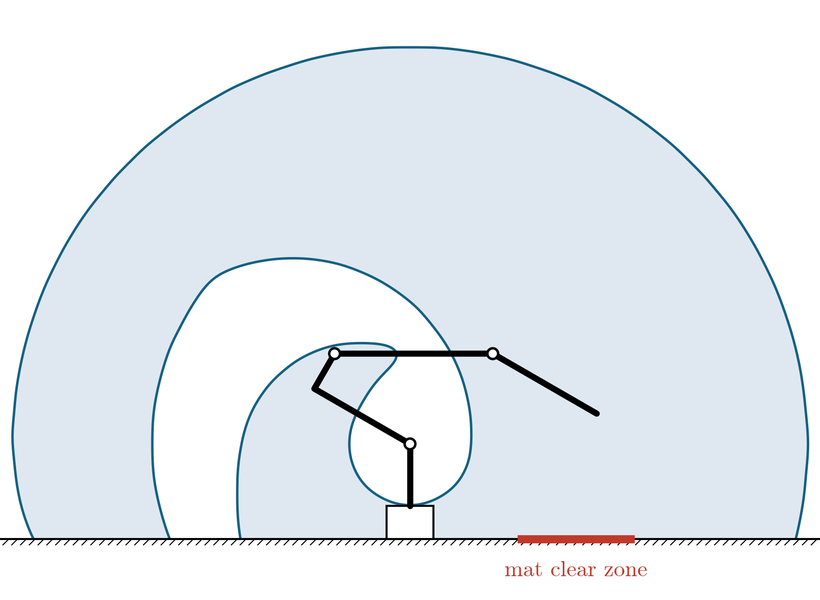

*Side view at q1 = 0: the tips of random (q2, q3, q4) inside the joint limits, above the mat. Most of the white
    regions inside the envelope are cut out by the joint limits; a finite sample also leaves gaps of its own. Red: the mat's clear zone,
    x = 110 to 230 mm.*

In [ ]:
# --- worked case: 5000 random joint vectors -> tip positions -------------------------------------------------------------
rng = np.random.default_rng(0); N = 5000
qs = rng.uniform(Q_LIM[:, 0], Q_LIM[:, 1], size=(N, 4))
pts = omx.fkine(qs).t                                        # every tip at once (N x 3)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].plot(np.hypot(pts[:, 0], pts[:, 1]), pts[:, 2], '.', ms=1); ax[0].axhline(0, color='k'); ax[0].set_xlabel('r (m)'); ax[0].set_ylabel('z (m)'); ax[0].set_title('side (r, z)'); ax[0].axis('equal')
ax[1].plot(pts[:, 0], pts[:, 1], '.', ms=1); ax[1].set_xlabel('x (m)'); ax[1].set_ylabel('y (m)'); ax[1].set_title('top'); ax[1].axis('equal')
plt.show()

<br>

<a id='arm'></a>

### 3.5 On the arm: the model against the arm (arm)
---

From here on you need the arm, or the digital twin (`SIMULATE = True` in the next cell). Connect, re-estimate the camera's intrinsics,
and re-measure the camera mount `T_EC` of this arm (your Lab 2 method, run for you).

In [ ]:
# --- connect to the arm --------------------------------------------------------------------------------------------
# Safe to re-run: an existing connection is closed first, so the COM port is released before it is opened again.
# SIMULATE = True runs the MuJoCo digital twin (omx_mujoco.py) instead of the real arm: same API, a rendered
# wrist camera, and optional hidden model errors so you can test calibration against ground truth.
SIMULATE = False
PORT = 'auto'                  # finds the OpenRB-150 by its USB id; or set it, e.g. 'COM4' (Device Manager) / '/dev/ttyACM0'
# --- which arm are you on today? Read the asset label on the base. Everything you measure is tagged with it,
#     because zero offsets, camera intrinsics and the camera mount are all properties of THIS arm.
ARM_ID = 'OMX-00'            # EDIT every session
if 'arm' in globals():
    try:
        arm.close()
    except Exception as e:
        print('closing the previous connection:', e)
    del arm
if SIMULATE:
    from omx_mujoco import OMXSim, SimCamera
    arm = OMXSim(view=True)    # view=False if no display; set kin_error=..., joint_offsets=... to hide errors
    # Video: arm.record('run.mp4') writes the wrist camera and a scene camera side by side (same size) while the arm
    # moves; arm.stop_recording() when done.
else:
    arm = OMX(PORT)
print('connected:', 'digital twin' if SIMULATE else arm.port_name, '| arm', ARM_ID)

In [ ]:
# --- wrist camera: manual focus, may have been moved since last week -> re-estimate intrinsics NOW from the mat -------
# AUTO = True: the ARM calibrates the camera itself - it moves through 20 views aimed at the mat and takes a frame at
#   each once the joints and the image are static (omx_autocal.py; about 40 s). Torque goes ON and the arm MOVES:
#   keep hands, cables and objects out of the workspace. A live window shows each view.
# AUTO = False: move the camera over the mat by hand instead (torque off, live window, pause at each view).
# Re-run THIS cell on its own to repeat the calibration: the arm connection above is not touched.
# The gripper is left OPEN for all camera work (closed fingers hide the mat); arm.rest() closes it at the end of the lab.
AUTO = True
CAM_INDEX = 'Innomaker'         # the wrist camera by NAME (a laptop's own webcam is usually camera 0); or a number
if globals().get('cam') is not None:
    try:
        cam.close()                # release the camera held by the previous run
    except Exception:
        pass
cam = None
try:
    if SIMULATE:
        cam = SimCamera(arm); raise StopIteration      # twin: exact intrinsics, no per-session calibration needed
    cam = Camera(CAM_INDEX)
    import os
    import omx_camera
    _kb = [p for p in ('camera_K_baseline.npz', os.path.join(omx_camera.HERE, 'camera_K_baseline.npz')) if os.path.exists(p)]
    K0 = np.load(_kb[0])['K'] if _kb else None   # shared staff baseline (scripts/camera_K_baseline.npz): a starting guess only
    if AUTO:
        from omx_autocal import auto_calibrate
        print('Automatic calibration: the arm is about to move. Keep the workspace clear.')
        K, dist, rms = auto_calibrate(arm, cam, ARM_ID, K0=K0, show=True, stages=1, show_mount=False)   # stages=2: + planned views
    else:
        arm.torque(False)
        print('Torque is OFF. Move the camera over the mat by hand (up to 60 s), PAUSING at each view: vary its height between ~90 and 180 mm AND tilt the wrist')
        print('by at least +/-30 degrees (40 is better) - nearly vertical views at one height give a focal length 10-20% wrong.')
        # show=True opens a live window (press q to stop early); still_px keeps a frame only while you hold the camera still
        K, dist, rms = cam.calibrate_from_mat(n_frames=25, seconds=60, K0=K0, save_as=f'camera_K_session_{ARM_ID}.npz',
                                              show=True, still_px=1.5)
    if rms > 1.5: print('WARNING: rms > 1.5 px - check focus and that the mat is flat, then re-run this cell.')
except StopIteration:
    print('simulated wrist camera ready (K exact)')
except Exception as e:
    if cam is not None:
        try: cam.close()
        except Exception: pass
    cam = None; print('camera not available:', e)

In [ ]:
# --- camera mount on THIS arm, this session: your Lab 2 method (T_EC = inv(T_BE) T_BM inv(T_CM), mat frame = base frame) ---
# The arm visits a few poses that see the mat, then T_EC below is the MEASURED mount of this arm (T_EC_CAD is the design value).
def measure_mount(arm, cam, every=3):
    from omx_autocal import bootstrap_views
    arm.torque(True); arm.set_profile(40, 10); T_BEs, T_CMs = [], []
    for q in bootstrap_views()[::every]:
        arm.move_q(q, wait=True); time.sleep(0.4)
        T_CM, n = cam.mat_pose_avg(3)
        if T_CM is not None: T_BEs.append(omx.fkine(arm.read_q()).A); T_CMs.append(T_CM.A)
    arm.home(wait=True)
    if len(T_BEs) < 3: raise RuntimeError(f'only {len(T_BEs)} views saw the mat - check the camera cell')
    return SE3(mount_from_views(T_BEs, T_CMs), check=False), len(T_BEs)
if cam is None:
    T_EC = T_EC_CAD; print('no camera: T_EC is the design mount - camera-based results below use it unmeasured')
else:
    T_EC, n_mount = measure_mount(arm, cam)
    print(f'camera mount from {n_mount} views: optical axis {np.degrees(mount_tilt(T_EC)):.1f} deg below the tool '
          f'(design {np.degrees(mount_tilt(T_EC_CAD)):.0f}), camera at {np.round(T_EC.t * 1e3, 1)} mm in {{E}} (design {np.round(T_EC_CAD.t * 1e3, 1)})')

**Exercise 3.5: where should the tip be?** Use your `omx_fk` to predict the tip position at the test pose `q_test`, before the arm
moves there in the next cell. *Why:* the model is only useful if each joint turns the way it says. Knowing where the tip should end up
lets you spot a joint turning the wrong way as soon as it moves, and stop before anything hits.

In [ ]:
# --- Exercise 3.5: where should the tip be? -------------------------------------------------------------------------
q_test = np.array([0.5, 0.6, -0.4, 0.3])
p_pred = ...                       # the tip position at q_test from your omx_fk (m)
try_it('predicted tip at q_test', p_pred, omx.fkine(q_test).t)

<details><summary><b>Hint</b></summary>

`omx_fk` returns the 4x4 pose; the position is the top of the last column, `[:3, 3]`.

</details>

In [ ]:
# the arm goes there gently; watch it: joint 1 turns left (+y), joints 2-4 pitch nose down
arm.torque(True); arm.set_profile(40, 10)
arm.move_q(q_test, wait=True); time.sleep(0.5)
q_meas = arm.read_q()
print('commanded (deg):', np.round(np.degrees(q_test), 1), '\nmeasured  (deg):', np.round(np.degrees(q_meas), 1))
print(f'tip from the model at the measured angles: {np.round(1e3 * omx.fkine(q_meas).t, 1)} mm (left of the base: y > 0)')
arm.home(wait=True)

> If a joint turned the *opposite* way to the model (the tip went right instead of left, or up instead of down), stop and call a
> demonstrator: the sign belongs in `omx.py`, not in your model.

<br>

<a id='camera'></a>

### 3.6 On the arm: the camera as an instrument (arm)
---

The model is nominal: your arm has servo zero offsets, slightly different links, its own camera mount and a mat that is not exactly
where the model assumes. The wrist camera measures the gap. It measures the mat's pose ${}^{C}\mathbf{T}_{M}$; the model predicts it
from the joint angles and the mount you measured:

$$ {}^{C}\hat{\mathbf{T}}_{M} = \left({}^{B}\mathbf{T}_{E}(q)\,{}^{E}\mathbf{T}_{C}\right)^{-1}\,{}^{B}\mathbf{T}_{M} \qquad (6) $$

Turned round, each view also says where the camera thinks the end-effector point is on the mat (`tip_in_mat`). Comparing that with
the model's tip at the measured angles gives one error vector per pose. First the three points you placed by hand in Lab 2.

In [ ]:
import json, os
if os.path.exists('lab2_refs.json'):
    d = json.load(open('lab2_refs.json')); T_BM = SE3(np.array(d['T_BM']))
    for ref in d['refs']:
        p_pred = (T_BM.inv() * omx.fkine(np.array(ref['q'])).t).ravel()
        print('hand-placed (mat):', np.round(ref['p_M'], 3), ' model (mat):', np.round(p_pred, 3), ' error (mm):', np.round(1e3 * np.linalg.norm(p_pred - ref['p_M']), 1))
else:
    T_BM = SE3(); print('no lab2_refs.json in data/ (Lab 2 Section 2.6 writes it): the mat is taken as nominal, T_BM = I')

### Task 3 — Validation statistics and the error field
Given arrays `pred` and `meas` (N x 3, metres, mat frame) of where the model says the end-effector point is and where the camera
says it is, write `error_stats(pred, meas)` → `[mean_mm, max_mm, bias_x_mm, bias_y_mm]` (bias = mean of meas - pred). Then write
`plot_error_field(pred, meas)`: a top view of the mat with an arrow from each predicted point to its measured point, scaled x10 so
millimetre errors are visible. Section 3.6 runs both on your twelve measurements.

In [ ]:
def error_stats(pred, meas):
    """N x 3 arrays (m) -> [mean_mm, max_mm, bias_x_mm, bias_y_mm]."""
    # TODO: write your implementation here
    raise NotImplementedError

def plot_error_field(pred, meas, scale=10):
    """Top view: arrows from predicted to measured, exaggerated by `scale`."""
    # TODO: write your implementation here
    raise NotImplementedError


In [ ]:
# --- self-check (hidden expected values) ---------------------------------------------------------
check('error_stats on a canned set', lambda: error_stats(np.array([[0.10,0,0.09],[0.15,0.05,0.09],[0.18,-0.06,0.09]]), np.array([[0.1012,0.0005,0.0895],[0.1518,0.0508,0.0906],[0.1823,-0.0592,0.0888]])), '098e20345b', decimals=3)

<details><summary><b>Hint</b></summary>

With `d = meas - pred` (N x 3), `np.linalg.norm(d, axis=1)` gives one error per pose: take its mean and max. The bias is the mean of
each column of `d`, x and y. Multiply by 1000 for millimetres. For the plot, `plt.quiver(pred[:, 0], pred[:, 1], d[:, 0], d[:, 1],
angles='xy', scale_units='xy', scale=0.1)` draws each arrow ten times its length.

</details>

In [ ]:
# twelve poses over the mat, the tool pitched so the camera (measured mount T_EC) looks straight down from ~180 mm
targets = [(x, y) for x in (0.12, 0.15, 0.18, 0.21) for y in (-0.06, 0.0, 0.06)]
arm.torque(True); arm.set_profile(30, 10)
rows = []
for (x, y) in targets:
    q = omx_ik((T_BM * [x, y, CAM_HOVER]).ravel(), pitch=look_down_pitch(T_EC), elbow='any')
    if q is None: print('unreachable', x, y); continue
    arm.move_q(q, wait=True); time.sleep(0.6)
    q_meas = arm.read_q()
    T_CM, n = cam.mat_pose_avg(5)
    if T_CM is None: print('no markers at', x, y); continue
    et, er = pose_error(T_CM, predicted_T_CM(omx, q_meas, T_EC, T_BM))
    p_tip_meas = tip_in_mat(T_CM, T_EC, P_TIP_E)                   # where the camera says the EE point is
    p_tip_model = (T_BM.inv() * omx.fkine(q_meas).t).ravel()       # where the model says it is
    rows.append(dict(q=q_meas.tolist(), T_CM=T_CM.A.tolist(), n=n, err_mm=1e3 * et, err_deg=np.degrees(er),
                     tip_meas=np.ravel(p_tip_meas).tolist(), tip_model=p_tip_model.tolist()))
    print(f'({x:.2f},{y:.2f}) {n} frames | pose error {1e3 * et:5.1f} mm {np.degrees(er):4.2f} deg | EE point: camera {np.round(np.ravel(p_tip_meas) * 1e3, 1)} vs model {np.round(p_tip_model * 1e3, 1)} mm')
arm.home(wait=True)
json.dump(dict(arm=ARM_ID, T_EC=T_EC.A.tolist(), rows=rows), open(f'lab3_validation_{ARM_ID}.json', 'w'))
pred = np.array([r_['tip_model'] for r_ in rows]); meas = np.array([r_['tip_meas'] for r_ in rows])
print('[mean, max, bias_x, bias_y] (mm):', np.round(error_stats(pred, meas), 2)); plot_error_field(pred, meas)

**Exercise 3.6a: offset or growth with reach?** Compute the error at each pose and fit a straight line of error against reach.
*Why:* the shape of the error field says where it comes from. A constant offset points at the mat placement or the camera mount; an
error that grows with reach points at a link length or a joint offset; one that turns with yaw points at joint 1. The slope tells you
which kind your arm has, and so what a calibration has to fix.

In [ ]:
# --- Exercise 3.6a: offset or growth with reach? --------------------------------------------------------------------
err_mm = ...                       # |meas - pred| for each pose, mm (N,)
reach = ...                        # each predicted point's distance from the joint-1 axis, m (N,)
slope = ...                        # the straight-line fit of err_mm against reach: mm per 100 mm of reach (np.polyfit)
from scipy.stats import linregress
_e = 1e3 * np.linalg.norm(meas - pred, axis=1); _r = np.hypot(pred[:, 0], pred[:, 1])
try_it('error at each pose (mm)', err_mm, _e)
try_it('growth with reach (mm per 100 mm)', slope, 0.1 * linregress(_r, _e).slope)

<details><summary><b>Hint</b></summary>

`np.linalg.norm(..., axis=1)` gives one length per row; the reach uses only the x and y columns of `pred`. `np.polyfit(reach, err_mm, 1)`
returns `[slope, intercept]`, the slope in mm per metre of reach: multiply by 0.1 for mm per 100 mm.

</details>

**Trust, but verify (bench).** The camera's answer depends on the mount `T_EC` measured at the start. At two of the poses, lower the tip
onto the mat by hand (torque off, support the arm) and read its position off the grid with the ruler; set the two readings in the cell
below (metres) and run it. In the twin, the "ruler" is the twin's true tool position.

In [ ]:
RULER_FIRST = ...       # EDIT on the bench: ruler reading (x, y) of the tip at the FIRST pose, in metres, e.g. (0.152, 0.031)
RULER_LAST = ...        # EDIT on the bench: the same at the LAST pose
checks = []
for k, reading in ((0, RULER_FIRST), (len(rows) - 1, RULER_LAST)):
    if SIMULATE:
        arm.move_q(np.array(rows[k]['q']), wait=True)
        ruler = (T_BM.inv() * arm.true_T_BE()[:3, 3]).ravel()[:2]
    elif reading is ...:
        print(f'pose {k}: set its ruler reading above first'); continue
    else:
        ruler = np.array(reading, float)
    checks.append(1e3 * (np.array(rows[k]['tip_meas'][:2]) - ruler))
    print(f'pose {k}: camera minus ruler = {np.round(checks[-1], 1)} mm')
if SIMULATE: arm.home(wait=True)

**Exercise 3.6b: what can a calibration fix?** For each source of error in the list, decide whether changing a number in the model can
remove it. *Why:* the assignment calibrates your model by changing its numbers. Knowing which errors that can and cannot remove tells
you what will be left after you calibrate.

In [ ]:
# --- Exercise 3.6b: what can a calibration fix? ---------------------------------------------------------------------
# The assignment calibrates the model by changing its NUMBERS. Which of these sources of error can that remove?
sources = ['servo zero offsets', 'link lengths', 'the camera mount', 'where the mat lies', 'gear backlash', 'links bending under load']
fixable = [..., ..., ..., ..., ..., ...]   # True if a constant in the model can absorb it
try_it('fixable by calibration', fixable, [True, True, True, True, False, False])

<details><summary><b>Hint</b></summary>

A constant can absorb an error that is the same every time the arm is at the same angles. Backlash changes with the direction the joint
arrived from; bending changes with the pose and the load. Lab 9 calibrates the fixable ones.

</details>

In [ ]:
# --- checkpoint: show this line to a demonstrator ------------------------------------------------------------------
s = error_stats(pred, meas)
print(f'ARM {ARM_ID} | {len(rows)} poses | camera vs model: mean {s[0]:.1f} mm, max {s[1]:.1f} mm, bias ({s[2]:.1f}, {s[3]:.1f}) mm | '
      f'saved lab3_validation_{ARM_ID}.json')

<br>

<a id='tb'></a>

### 3.7 The whole lab with the toolbox (desk)
---

What you built by hand, the way you will usually write it. Keep this cell as a reference for the assignment.

In [ ]:
from roboticstoolbox import ET
omx_ets = rtb.Robot(ET.tz(NOM['d1']) * ET.Rz() * ET.Ry() * ET.tz(NOM['l2z']) * ET.tx(NOM['l2x'])
                    * ET.Ry() * ET.tx(NOM['l3']) * ET.Ry() * ET.tx(NOM['l4']), name='OMX')         # 3.2  equation (4)
q_home = np.radians([0, -60, 60, 30])
print('3.2  B_T_E at home:'); print(omx_ets.fkine(q_home))
print('3.3  D-H vs ETS at home, position difference (m):', np.linalg.norm(omx_dh().fkine(q_home).t - omx_ets.fkine(q_home).t))
print('3.3  the end frames differ by R_x(90 deg):', np.allclose((omx_dh().fkine(q_home) * SE3.Rx(np.pi / 2)).A, omx_ets.fkine(q_home).A))
qs = np.random.default_rng(0).uniform(Q_LIM[:, 0], Q_LIM[:, 1], size=(2000, 4))
print('3.4  furthest reach (mm):', np.round(1e3 * np.linalg.norm(omx_ets.fkine(qs).t[:, :2], axis=1).max()))

## Before you leave
1. Park the arm (`arm.rest()`: the folded rest pose, where it stays put with torque off), then `arm.torque(False)` and `arm.close()`.
   Never switch torque off at home or mid-task: the arm drops under gravity.
2. Switch off the bench power supply and tidy cables.
3. Show your checkpoint output to a demonstrator for sign-off.
4. Commit this notebook and any data files to your own LABS repository and **push** (Sync Changes): later labs read them. The assessment repository (issued in week 6) starts fresh; copy across any code you want to reuse.

In [ ]:
arm.set_profile(40, 10); arm.rest(wait=True)     # folded rest pose: stable with torque off
arm.torque(False)
arm.close()
if globals().get('cam') is not None: cam.close()